# EV charging station siting in NCT Delhi: grid, K-means and MCLP
One notebook. All models, scenarios and sensitivity runs. Run top to bottom from the project folder.

**Main demand weight: EV registrations + destinations** (`CFG["weight"] = "ev"`). Home demand R = each cell's population x its ward's VAHAN EV-4W registrations per resident (EV cars + e-taxis, 2020-26, allocated by RTO zone). The population-only version is kept as a sensitivity surface (section 11). Supersedes `ev_kmeans_model_v2.ipynb`, `ev_mclp_model.ipynb`, `ev_evaluation_and_extensions.ipynb`, `ev_grid_baseline_updated.ipynb`.

Inputs: `Final Data/` and `data/delhi_demand_weights*.gpkg`. Outputs: `outputs/final/` (new files only).

## 0. Setup

In [1]:
import time, warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import box, Polygon
from shapely.ops import nearest_points
import matplotlib.pyplot as plt
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.sparse import csr_matrix, coo_matrix, hstack, eye
from scipy.sparse.csgraph import dijkstra, connected_components
from scipy.spatial import cKDTree
from scipy.optimize import linear_sum_assignment
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

Settings. Team decisions are in `Final Data/ASSUMPTIONS.md` (codes D1 to D3, M1, M2).

In [2]:
CFG = dict(
    crs="EPSG:32643",
    gis="Final Data/delhi_ev_gis_v1.gpkg",
    master="Final Data/delhi_ev_master_wards_v1.csv",
    candidates="Final Data/model_inputs/candidates_v1.csv",
    chargers="Final Data/model_inputs/existing_chargers_v1.csv",
    road="Final Data/delhi_road_network_v1.gpkg",
    osm="delhi.osm.pbf",
    demand="data/delhi_demand_weights.gpkg",          # 1 km cells (main)
    demand_500="data/delhi_demand_weights_500m.gpkg", # 500 m cells (sensitivity)
    rebuild_demand=True,      # rebuild the 1 km layer from OSM (about 20 s) and check it matches the file
    run_road=True,            # road-network distances (needs the 230 MB road file)
    weight="ev",              # "ev" (60% EV registrations + 40% destinations; main, follows the proposal) or "team" (population in place of EV)
    P=104,                    # stations per method (D1)
    R=2100,                   # coverage radius, m, straight line (D1)
    R_tie=1000,               # MCLP tie-break radius, m
    grid_km=[3, 2, 1],
    thresholds=[0.01, 0.05, 0.10, 0.20, 0.30],
    radii=[1500, 2100, 3000],
    budgets=[104, 157, 178, 206, 404],
    seed=42, n_init=20, n_seeds=10,
    mc_runs=50, mc_sigma=0.30, mc_lam=(0.3, 0.8), mc_conc=50.0, robust=0.8,
    tl_fast=300, tl_slow=600, tl_budget=180,          # solver time limits, s
    out="outputs/final",
)
CRS, P, R = CFG["crs"], CFG["P"], CFG["R"]
OUT = Path(CFG["out"]); OUT.mkdir(parents=True, exist_ok=True)
TIMES = {}                    # solve times for the computational-cost table
rng_master = np.random.default_rng(CFG["seed"])

## 1. Helpers

In [3]:
def xy(g):
    return np.column_stack([g.geometry.x.to_numpy(), g.geometry.y.to_numpy()])

def pts(df, x="x", y="y"):
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df[x], df[y]), crs=CRS)

def nearest(P_, S):
    return cKDTree(S).query(P_)[0]

def wq(v, ww, q):
    o = np.argsort(v); c = np.cumsum(ww[o]) / ww.sum()
    return float(v[o][np.searchsorted(c, q)])

def cov(S, P_, wt, r=R):
    return 100 * wt[nearest(P_, S) <= r].sum() / wt.sum()

def agree(A, B_, r=1000):
    """Share of A's stations with a B station within r."""
    return 100 * (nearest(A, B_) <= r).mean()

class Timer:
    def __init__(self, key): self.key = key
    def __enter__(self): self.t = time.time()
    def __exit__(self, *a): TIMES[self.key] = time.time() - self.t

## 2. Demand layer
1 km cells. Weight = 60% home demand R + 40% destination demand D (team build, `demand_weights.ipynb`). With `weight="ev"` (main), R is replaced by EV registrations in section 3; D is unchanged.
Rebuilt from OSM below and checked against the saved file (turn off with `rebuild_demand=False`).

In [4]:
THETA_D = {"poi": 0.35, "land": 0.30, "road": 0.20, "transit": 0.15}
THETA_POI = {"office": 0.25, "mall": 0.25, "hospital": 0.20, "hotel": 0.15, "parking": 0.15}
LAMBDA, N_TOTAL = 0.6, 1000.0

def dw_destination(df, td=THETA_D, tp=THETA_POI):
    poi = sum(tp[k] * df[f"Dm_{k}"] for k in tp)
    road = (df["Dm_art_density"] + df["Dm_int_density"] + df["Dm_art_prox"]) / 3
    return td["poi"] * poi + td["land"] * df["Dm_ci_land"] + td["road"] * road + td["transit"] * df["Dm_transit_prox"]

def dw_recompute(df, lam=LAMBDA, td=THETA_D, tp=THETA_POI, N=N_TOTAL, R_col="R"):
    Rv = df[R_col].to_numpy(float); Dv = dw_destination(df, td, tp).to_numpy(float)
    s = lam * Rv / Rv.sum() + (1 - lam) * Dv / Dv.sum()
    return N * s / s.sum()

def dw_mc(df, rng, sigma=0.30, lam_range=(0.3, 0.8), conc=50.0, R_col="R"):
    """One Monte Carlo draw: lambda ~ U, theta ~ Dirichlet, lognormal noise."""
    lam = rng.uniform(*lam_range)
    kd, kp = list(THETA_D), list(THETA_POI)
    td = dict(zip(kd, rng.dirichlet(conc * np.array([THETA_D[k] for k in kd]))))
    tp = dict(zip(kp, rng.dirichlet(conc * np.array([THETA_POI[k] for k in kp]))))
    w_ = dw_recompute(df, lam, td, tp, R_col=R_col) * rng.lognormal(0, sigma, len(df))
    return N_TOTAL * w_ / w_.sum()

In [5]:
GIS, MASTER, OSM = CFG["gis"], CFG["master"], CFG["osm"]
def build_demand_layer(cell_m, out_path):
    """Team demand layer (demand_weights.ipynb logic, unchanged). Writes a new GeoPackage."""
    CFG = dict(wards_path=GIS, wards_layer="wards", study_layer="study_area", ward_csv=MASTER, osm_path=OSM,
               crs=CRS, cell_m=cell_m, boundary_close_m=300, min_piece_m2=1.0, dest_unit="cell", res_min_cover=0.01,
               dedup_m=50, edge_buffer_m=5000, lam=LAMBDA, N=N_TOTAL, theta_D=THETA_D, theta_POI=THETA_POI)
    QA = {}
    wards = gpd.read_file(CFG["wards_path"], layer=CFG["wards_layer"]).to_crs(CRS)[["ward_no", "ward_name", "geometry"]]
    wt = pd.read_csv(CFG["ward_csv"])[["ward_no", "ward_name", "population", "area_km2", "income_total_inr"]]
    chk = wards.merge(wt, on="ward_no", how="outer", indicator=True, suffixes=("_poly", "_csv"))
    QA["ward_match"] = dict(
        n_poly=len(wards), n_csv=len(wt),
        matched=int((chk["_merge"] == "both").sum()),
        name_mismatch=int((chk["ward_name_poly"] != chk["ward_name_csv"]).sum()),
        max_area_diff_km2=float((chk.geometry.area / 1e6 - chk["area_km2"]).abs().max()),
    )
    assert QA["ward_match"]["matched"] == 250, QA["ward_match"]
    print("Ward check:", QA["ward_match"])
    wards = wards.merge(wt[["ward_no", "population", "income_total_inr"]], on="ward_no")

    study = gpd.read_file(CFG["wards_path"], layer=CFG["study_layer"]).to_crs(CRS)
    study_geom = shapely.make_valid(study.union_all())
    # display outline per brief (holes filled); NOT used for clipping, so the NDMC hole stays excluded
    _b = wards.union_all().buffer(CFG["boundary_close_m"]).buffer(-CFG["boundary_close_m"])
    outline = gpd.GeoDataFrame(geometry=[shapely.union_all([Polygon(p.exterior) for p in getattr(_b, "geoms", [_b])])], crs=CRS)
    edge_geom = study_geom.buffer(CFG["edge_buffer_m"])
    print(f"Study area {study_geom.area/1e6:,.0f} km2 | filled outline {outline.area.iloc[0]/1e6:,.0f} km2")
    cm = CFG["cell_m"]
    minx, miny, maxx, maxy = study_geom.bounds
    x0, y0 = np.floor(minx / cm) * cm, np.floor(miny / cm) * cm
    xs, ys = np.arange(x0, maxx, cm), np.arange(y0, maxy, cm)
    cells = gpd.GeoDataFrame(
        [{"cell_id": f"c{int(x/cm)}_{int(y/cm)}", "ix": int(x / cm), "iy": int(y / cm)} for y in ys for x in xs],
        geometry=[box(x, y, x + cm, y + cm) for y in ys for x in xs], crs=CRS)
    cells = cells[cells.intersects(study_geom)].reset_index(drop=True)

    pieces = gpd.overlay(cells, wards[["ward_no", "geometry"]], how="intersection", keep_geom_type=True)
    pieces["area_m2"] = pieces.area
    n_sliver = int((pieces["area_m2"] < CFG["min_piece_m2"]).sum())
    pieces = pieces[pieces["area_m2"] >= CFG["min_piece_m2"]].reset_index(drop=True)
    pieces["piece_id"] = np.arange(len(pieces))
    pieces["area_km2"] = pieces["area_m2"] / 1e6
    QA["units"] = dict(cell_m=cm, n_cells=int(pieces["cell_id"].nunique()), n_pieces=len(pieces),
                       slivers_dropped=n_sliver, pieces_area_km2=round(pieces["area_km2"].sum(), 2),
                       wards_area_km2=round(wards.area.sum() / 1e6, 2))
    print(QA["units"])
    def tag(s, key):
        """Value of `key` from an OSM hstore string column (NaN if absent)."""
        return s.str.extract(rf'"{key}"=>"([^"]*)"', expand=False)


    t0 = time.time()
    P = CFG["osm_path"]
    pts = gpd.read_file(P, layer="points", where="other_tags IS NOT NULL").to_crs(CRS)
    pts = pts[pts.within(edge_geom)].reset_index(drop=True)
    for k in ["amenity", "shop", "tourism", "office", "building", "power", "railway", "station",
              "subway", "public_transport", "network"]:
        pts[k] = tag(pts["other_tags"], k)

    mp = gpd.read_file(P, layer="multipolygons",
                       where="building IS NULL OR building<>'yes' OR amenity IS NOT NULL OR shop IS NOT NULL "
                             "OR office IS NOT NULL OR tourism IS NOT NULL").to_crs(CRS)
    mp = mp[mp.intersects(edge_geom)].reset_index(drop=True)
    for k in ["power", "railway", "station", "subway", "public_transport", "network"]:
        mp[k] = tag(mp["other_tags"], k)

    ln = gpd.read_file(P, layer="lines", where="highway IS NOT NULL", columns=["osm_id", "highway"]).to_crs(CRS)
    ln = ln[ln.intersects(edge_geom)].reset_index(drop=True)
    print(f"OSM read in {time.time()-t0:.0f}s | points {len(pts):,} | polygons {len(mp):,} | road lines {len(ln):,} "
          f"(within study area + {CFG['edge_buffer_m']/1000:.0f} km)")
    LU = {"residential": ["residential"], "commercial": ["commercial", "retail"], "industrial": ["industrial"]}
    lu = mp[mp["landuse"].isin(sum(LU.values(), []))][["landuse", "geometry"]].copy()
    lu["cls"] = lu["landuse"].map({v: k for k, vs in LU.items() for v in vs})
    lu["geometry"] = shapely.make_valid(lu.geometry.values)
    lu = lu.explode(index_parts=False)
    lu = lu[lu.geom_type.isin(["Polygon", "MultiPolygon"])]
    lu = lu.dissolve("cls").reset_index()[["cls", "geometry"]].explode(index_parts=False)   # overlaps within a class removed
    lu = lu.clip(study_geom)

    ov = gpd.overlay(pieces[["piece_id", "geometry"]], lu, how="intersection", keep_geom_type=True)
    ov["a"] = ov.area
    lu_area = ov.pivot_table(index="piece_id", columns="cls", values="a", aggfunc="sum").reindex(pieces["piece_id"]).fillna(0)
    for c in LU:
        pieces[f"lu_{c}_m2"] = lu_area.get(c, 0).to_numpy()
        pieces[f"lu_{c}_share"] = (pieces[f"lu_{c}_m2"] / pieces["area_m2"]).clip(0, 1)
    pieces["lu_ci_share"] = (pieces["lu_commercial_share"] + pieces["lu_industrial_share"]).clip(0, 1)
    QA["landuse_km2"] = {c: round(pieces[f"lu_{c}_m2"].sum() / 1e6, 2) for c in LU}
    print("Mapped land use in study area (km2):", QA["landuse_km2"])
    def dedup(pt, pg, d=CFG["dedup_m"]):
        pt = pt[["geometry"]].reset_index(drop=True)
        pg = pg[["geometry"]].reset_index(drop=True)
        cen = gpd.GeoDataFrame(geometry=pg.geometry.centroid, crs=CRS)
        drop = set()
        if len(pg) and len(pt):
            drop |= set(gpd.sjoin(pt, pg, predicate="within").index)
            drop |= set(gpd.sjoin_nearest(pt, cen, max_distance=d).index)
        out = pd.concat([pt.drop(index=list(drop)).assign(src="point"), cen.assign(src="polygon")], ignore_index=True)
        return gpd.GeoDataFrame(out, geometry="geometry", crs=CRS), len(drop)


    RULES = {   # category: (points mask, polygons mask)
        "office":   (pts["office"].notna() | (pts["building"] == "office"), mp["office"].notna() | (mp["building"] == "office")),
        "mall":     (pts["shop"] == "mall", mp["shop"] == "mall"),
        "hospital": (pts["amenity"] == "hospital", mp["amenity"] == "hospital"),
        "hotel":    (pts["tourism"] == "hotel", mp["tourism"] == "hotel"),
        "parking":  (pts["amenity"] == "parking", mp["amenity"] == "parking"),
        # feasibility / supply (NOT scored)
        "fuel":       (pts["amenity"] == "fuel", mp["amenity"] == "fuel"),
        "substation": (pts["power"] == "substation", mp["power"] == "substation"),
        "charging":   (pts["amenity"] == "charging_station", mp["amenity"] == "charging_station"),
    }
    POI_CATS = list(CFG["theta_POI"])
    poi, poi_qa = {}, []
    for cat, (mpt, mpg) in RULES.items():
        g, n_drop = dedup(pts[mpt], mp[mpg])
        g = g[g.within(study_geom)].reset_index(drop=True)
        poi[cat] = g
        poi_qa.append(dict(category=cat, scored=cat in POI_CATS,
                           points_in_area=int(pts[mpt].within(study_geom).sum()),
                           polygons_in_area=int(mp[mpg].centroid.within(study_geom).sum()),
                           duplicates_dropped=n_drop, final=len(g)))
    poi_qa = pd.DataFrame(poi_qa)
    poi_qa.loc[poi_qa["category"] == "substation", "note"] = "UNRELIABLE: OSM substations heavily undercounted"
    poi_qa.loc[poi_qa["category"] == "parking", "note"] = "undercounted in OSM; also a feasible site"
    poi_qa
    pc = pieces[["piece_id", "geometry"]]
    for cat in POI_CATS:
        j = gpd.sjoin(poi[cat], pc, predicate="within")
        pieces[f"n_{cat}"] = pieces["piece_id"].map(j.groupby("piece_id").size()).fillna(0).astype(int)
        pieces[f"dens_{cat}"] = pieces[f"n_{cat}"] / pieces["area_km2"]
    pieces[[f"n_{c}" for c in POI_CATS]].sum()
    ART = ["motorway", "trunk", "primary", "secondary"]
    DRIVE = ART + ["tertiary", "unclassified", "residential", "living_street",
                   "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link"]

    art = ln[ln["highway"].isin(ART)].reset_index(drop=True)
    ai = gpd.overlay(art[["geometry"]], pc, how="intersection", keep_geom_type=True)
    ai["km"] = ai.length / 1000
    pieces["art_km"] = pieces["piece_id"].map(ai.groupby("piece_id")["km"].sum()).fillna(0)
    pieces["art_density"] = pieces["art_km"] / pieces["area_km2"]

    drv = ln[ln["highway"].isin(DRIVE)].geometry.values
    xy, idx = shapely.get_coordinates(drv, return_index=True)
    is_end = np.r_[True, idx[1:] != idx[:-1]] | np.r_[idx[1:] != idx[:-1], True]
    nodes = pd.DataFrame({"x": np.round(xy[:, 0], 2), "y": np.round(xy[:, 1], 2), "deg": np.where(is_end, 1, 2)})
    nodes = nodes.groupby(["x", "y"], as_index=False)["deg"].sum()
    inter = nodes[nodes["deg"] >= 3]
    inter = gpd.GeoDataFrame(geometry=gpd.points_from_xy(inter["x"], inter["y"]), crs=CRS)
    ji = gpd.sjoin(inter, pc, predicate="within")
    pieces["n_intersections"] = pieces["piece_id"].map(ji.groupby("piece_id").size()).fillna(0).astype(int)
    pieces["int_density"] = pieces["n_intersections"] / pieces["area_km2"]
    QA["roads"] = dict(arterial_km_in_area=round(pieces["art_km"].sum(), 1),
                       intersections_in_area=int(pieces["n_intersections"].sum()))

    cent = gpd.GeoDataFrame(pieces[["piece_id"]], geometry=pieces.geometry.centroid, crs=CRS)
    d = gpd.sjoin_nearest(cent, art[["geometry"]], distance_col="d").groupby("piece_id")["d"].min()
    pieces["dist_arterial_m"] = pieces["piece_id"].map(d)

    is_metro_pt = pts["railway"].eq("station") | pts["public_transport"].eq("station")
    is_metro_pt &= pts["station"].eq("subway") | pts["subway"].eq("yes") | pts["network"].str.contains("Metro", na=False)
    is_metro_pg = (mp["railway"].eq("station") | mp["public_transport"].eq("station")) & \
                  (mp["station"].eq("subway") | mp["subway"].eq("yes") | mp["network"].str.contains("Metro", na=False))
    transit = pd.concat([
        pts.loc[is_metro_pt, ["geometry"]].assign(kind="metro"),
        gpd.GeoDataFrame(geometry=mp.loc[is_metro_pg].centroid, crs=CRS).assign(kind="metro"),
        pts.loc[pts["amenity"] == "bus_station", ["geometry"]].assign(kind="bus_terminal"),
        gpd.GeoDataFrame(geometry=mp.loc[mp["amenity"] == "bus_station"].centroid, crs=CRS).assign(kind="bus_terminal"),
    ], ignore_index=True)
    transit = gpd.GeoDataFrame(transit, geometry="geometry", crs=CRS)
    d = gpd.sjoin_nearest(cent, transit[["geometry"]], distance_col="d").groupby("piece_id")["d"].min()
    pieces["dist_transit_m"] = pieces["piece_id"].map(d)
    QA["transit"] = transit.assign(in_area=transit.within(study_geom)).groupby("kind")["in_area"].agg(["size", "sum"]) \
        .rename(columns={"size": "within_area_plus_buffer", "sum": "within_study_area"}).to_dict("index")
    print(QA["roads"], QA["transit"])
    g = pieces.groupby("ward_no")
    ward_res = g["lu_residential_m2"].transform("sum")
    ward_area = g["area_m2"].transform("sum")
    pieces["r_fallback"] = (ward_res <= 0) | (ward_res < CFG["res_min_cover"] * ward_area)
    pieces["r_share"] = np.where(pieces["r_fallback"], pieces["area_m2"] / ward_area,
                                 pieces["lu_residential_m2"] / ward_res.where(~pieces["r_fallback"], 1))
    pieces = pieces.merge(wards[["ward_no", "income_total_inr", "population"]], on="ward_no", how="left")
    pieces["R"] = pieces["income_total_inr"] * pieces["r_share"]
    pieces["pop_alloc"] = pieces["population"] * pieces["r_share"]

    mass = pieces.groupby("ward_no").agg(R=("R", "sum"), tot=("income_total_inr", "first"),
                                         res_km2=("lu_residential_m2", lambda s: s.sum() / 1e6),
                                         area_km2=("area_km2", "sum"), fallback=("r_fallback", "first"))
    mass["rel_err"] = (mass["R"] / mass["tot"] - 1).abs()
    mass["res_cover"] = mass["res_km2"] / mass["area_km2"]
    QA["mass"] = dict(max_rel_err=float(mass["rel_err"].max()),
                      total_R=float(pieces["R"].sum()), total_ward=float(wards["income_total_inr"].sum()),
                      n_fallback=int(mass["fallback"].sum()),
                      fallback_wards=mass.index[mass["fallback"]].tolist(),
                      n_no_res=int((mass["res_km2"] <= 0).sum()),
                      n_res_cover_lt_10pct=int(((mass["res_cover"] < 0.10) & ~mass["fallback"]).sum()),
                      median_res_cover=float(mass["res_cover"].median()))
    assert QA["mass"]["max_rel_err"] < 1e-9
    print({k: v for k, v in QA["mass"].items() if k != "fallback_wards"})
    def pct(x):
        """Plain percentile rank in [0, 1] (used for distances)."""
        x = pd.Series(x)
        return (x.rank(method="min") - 1) / (len(x) - 1)


    def pct_nz(x):
        """Zero-inflated features: 0 stays 0, nonzero ranked among nonzero only -> (0, 1]."""
        x = pd.Series(x)
        out = pd.Series(0.0, index=x.index)
        nz = x > 0
        out[nz] = x[nz].rank(method="average") / nz.sum()
        return out


    def cell_points(gdf):
        """Dissolve pieces to cells; point = centroid, or representative point if the centroid falls outside."""
        cg = gdf.dissolve("cell_id")[["geometry"]]
        p = cg.centroid
        out = ~p.within(cg.geometry)
        p[out] = cg.geometry[out].representative_point()
        return cg, p


    if CFG["dest_unit"] == "cell":
        cell_poly, cell_pt = cell_points(pieces)
        U = pieces.groupby("cell_id")[["area_m2", "area_km2", "art_km", "n_intersections", "lu_commercial_m2",
                                       "lu_industrial_m2"] + [f"n_{c}" for c in POI_CATS]].sum()
        for c in POI_CATS:
            U[f"dens_{c}"] = U[f"n_{c}"] / U["area_km2"]
        U["lu_ci_share"] = ((U["lu_commercial_m2"] + U["lu_industrial_m2"]) / U["area_m2"]).clip(0, 1)
        U["art_density"] = U["art_km"] / U["area_km2"]
        U["int_density"] = U["n_intersections"] / U["area_km2"]
        cp_ = gpd.GeoDataFrame({"cell_id": U.index}, geometry=cell_pt.reindex(U.index).values, crs=CRS)
        for col, tgt in [("dist_arterial_m", art), ("dist_transit_m", transit)]:
            U[col] = gpd.sjoin_nearest(cp_, tgt[["geometry"]], distance_col="d").groupby("cell_id")["d"].min()
        QA["edge_cells_small"] = int((U["area_m2"] < 0.25 * CFG["cell_m"] ** 2).sum())   # < 1/4 of a full cell
    else:
        U = pieces.set_index("piece_id")

    QA["zero_share"] = {c: round(float((U[v] == 0).mean()), 3) for c, v in
                        [*[(c, f"dens_{c}") for c in POI_CATS], ("ci_land", "lu_ci_share"),
                         ("art_density", "art_density"), ("int_density", "int_density")]}

    for c in POI_CATS:
        U[f"p_{c}"] = pct_nz(U[f"dens_{c}"])
    U["p_ci_land"] = pct_nz(U["lu_ci_share"])
    U["p_art_density"] = pct_nz(U["art_density"])
    U["p_int_density"] = pct_nz(U["int_density"])
    U["p_art_prox"] = pct(-U["dist_arterial_m"])
    U["p_transit_prox"] = pct(-U["dist_transit_m"])
    key = "cell_id" if CFG["dest_unit"] == "cell" else "piece_id"
    _PC = [f"p_{c}" for c in POI_CATS] + ["p_ci_land", "p_art_density", "p_int_density", "p_art_prox", "p_transit_prox"]
    for c in _PC:
        pieces[c] = pieces[key].map(U[c]).to_numpy()      # each piece takes its unit's score

    COMP = ["poi_idx", "land_idx", "road_idx", "transit_idx"]
    pieces["poi_idx"] = sum(CFG["theta_POI"][c] * pieces[f"p_{c}"] for c in POI_CATS)
    pieces["land_idx"] = pieces["p_ci_land"]
    pieces["road_idx"] = (pieces["p_art_density"] + pieces["p_int_density"] + pieces["p_art_prox"]) / 3
    pieces["transit_idx"] = pieces["p_transit_prox"]
    th = CFG["theta_D"]
    pieces["D_index"] = (th["poi"] * pieces["poi_idx"] + th["land"] * pieces["land_idx"]
                         + th["road"] * pieces["road_idx"] + th["transit"] * pieces["transit_idx"])
    pieces["D"] = pieces["D_index"] * pieces["area_km2"]

    # component masses: let weights be rebuilt for any lambda / theta (see demand_weights_mc.py)
    PCOLS = [f"p_{c}" for c in POI_CATS] + ["p_ci_land", "p_art_density", "p_int_density", "p_art_prox", "p_transit_prox"]
    for c in PCOLS:
        pieces["Dm_" + c[2:]] = pieces[c] * pieces["area_km2"]
    lam, N = CFG["lam"], CFG["N"]
    pieces["s"] = lam * pieces["R"] / pieces["R"].sum() + (1 - lam) * pieces["D"] / pieces["D"].sum()
    pieces["weight"] = N * pieces["s"] / pieces["s"].sum()
    assert np.allclose(dw_recompute(pieces), pieces["weight"])
    pieces[["R", "D", "s", "weight"]].describe().T
    SUM = ["area_m2", "area_km2", "R", "pop_alloc", "D", "s", "weight", "art_km", "n_intersections",
           "lu_residential_m2", "lu_commercial_m2", "lu_industrial_m2"] + [f"n_{c}" for c in POI_CATS] + \
          [c for c in pieces.columns if c.startswith("Dm_")]
    AWM = ["dist_arterial_m", "dist_transit_m", "D_index"] + COMP + PCOLS

    pa = pieces.copy()
    for c in AWM:
        pa[c] = pa[c] * pa["area_m2"]
    agg = pa.groupby("cell_id")[SUM + AWM].sum()
    agg[AWM] = agg[AWM].div(agg["area_m2"], axis=0)
    for c in POI_CATS:
        agg[f"dens_{c}"] = agg[f"n_{c}"] / agg["area_km2"]
    agg["art_density"] = agg["art_km"] / agg["area_km2"]
    agg["int_density"] = agg["n_intersections"] / agg["area_km2"]
    for c in ["residential", "commercial", "industrial"]:
        agg[f"lu_{c}_share"] = agg[f"lu_{c}_m2"] / agg["area_m2"]
    agg["lu_ci_share"] = agg["lu_commercial_share"] + agg["lu_industrial_share"]
    if CFG["dest_unit"] == "cell":                    # report the distances that were actually scored
        agg[["dist_arterial_m", "dist_transit_m"]] = U[["dist_arterial_m", "dist_transit_m"]]
    main = pieces.sort_values("area_m2").groupby("cell_id").tail(1).set_index("cell_id")
    agg["ward_no"] = main["ward_no"]
    agg["n_wards"] = pieces.groupby("cell_id")["ward_no"].nunique()
    agg["r_fallback_any"] = pieces.groupby("cell_id")["r_fallback"].any()

    cell_poly = pieces.dissolve("cell_id")[["geometry"]]
    pt = cell_poly.centroid
    inside = pt.within(cell_poly.geometry)
    pt[~inside] = cell_poly.geometry[~inside].representative_point()
    COLS = (["cell_id", "ward_no", "n_wards", "weight", "R", "D", "s", "pop_alloc", "D_index", "area_km2"]
            + COMP
            + [f"n_{c}" for c in POI_CATS] + [f"dens_{c}" for c in POI_CATS]
            + ["lu_residential_share", "lu_commercial_share", "lu_industrial_share", "lu_ci_share",
               "art_km", "art_density", "n_intersections", "int_density", "dist_arterial_m", "dist_transit_m"]
            + PCOLS + [c for c in agg.columns if c.startswith("Dm_")] + ["r_fallback_any"])
    demand_weights = gpd.GeoDataFrame(agg.join(pt.rename("geometry")).reset_index(), geometry="geometry", crs=CRS)[COLS + ["geometry"]]
    assert np.allclose(dw_recompute(demand_weights), demand_weights["weight"])
    assert abs(demand_weights["weight"].sum() - N) < 1e-6
    print(f"{len(demand_weights)} demand points | weight sum {demand_weights['weight'].sum():.1f}")
    demand_weights.head()
    cp = cell_poly.reset_index().merge(demand_weights[["cell_id", "R", "D", "weight"]], on="cell_id")
    gpkg = Path(out_path)
    if gpkg.exists():
        gpkg.unlink()                                  # this script owns this file; rebuilt each run
    demand_weights.to_file(gpkg, layer="demand_weights", driver="GPKG")
    gpd.GeoDataFrame(pieces.drop(columns=["geometry"]), geometry=pieces.geometry.centroid, crs=CRS) \
        .to_file(gpkg, layer="demand_pieces", driver="GPKG")
    cp.to_file(gpkg, layer="cells_polygons", driver="GPKG")
    for cat in ["parking", "fuel", "substation", "charging"]:
        poi[cat].to_file(gpkg, layer=f"feasible_{cat}" if cat != "charging" else "existing_charging_osm", driver="GPKG")
    transit.to_file(gpkg, layer="transit_nodes", driver="GPKG")
    outline.to_file(gpkg, layer="delhi_outline_filled", driver="GPKG")
    print("Saved", gpkg)
    return demand_weights, QA

In [6]:
if CFG["rebuild_demand"]:
    with Timer("demand rebuild"):
        rebuilt, _ = build_demand_layer(1000, OUT / "demand_rebuilt_1000m.gpkg")
    ref = gpd.read_file(CFG["demand"], layer="demand_weights")
    m_ = ref[["cell_id", "weight"]].merge(rebuilt[["cell_id", "weight"]], on="cell_id", suffixes=("_ref", "_new"))
    print(f"rebuild check: cells {len(rebuilt)} vs {len(ref)} | max weight diff {np.abs(m_.weight_ref - m_.weight_new).max():.2e}")

Ward check: {'n_poly': 250, 'n_csv': 250, 'matched': 250, 'name_mismatch': 0, 'max_area_diff_km2': 0.0}


Study area 1,393 km2 | filled outline 1,486 km2


{'cell_m': 1000, 'n_cells': 1570, 'n_pieces': 3259, 'slivers_dropped': 2, 'pieces_area_km2': np.float64(1393.25), 'wards_area_km2': np.float64(1393.25)}


OSM read in 4s | points 79,271 | polygons 41,108 | road lines 202,860 (within study area + 5 km)


Mapped land use in study area (km2): {'residential': np.float64(281.0), 'commercial': np.float64(14.69), 'industrial': np.float64(55.07)}


{'arterial_km_in_area': np.float64(1870.9), 'intersections_in_area': 166593} {'bus_terminal': {'within_area_plus_buffer': 65, 'within_study_area': 59}, 'metro': {'within_area_plus_buffer': 244, 'within_study_area': 194}}
{'max_rel_err': 3.3306690738754696e-16, 'total_R': 8095349065888.0, 'total_ward': 8095349065888.0, 'n_fallback': 33, 'n_no_res': 26, 'n_res_cover_lt_10pct': 41, 'median_res_cover': 0.31644718919005516}


1570 demand points | weight sum 1000.0
Saved outputs/final/demand_rebuilt_1000m.gpkg


rebuild check: cells 1570 vs 1570 | max weight diff 0.00e+00


## 3. Load data

In [7]:
master = pd.read_csv(CFG["master"]).set_index("ward_no")
study = gpd.read_file(CFG["gis"], layer="study_area").to_crs(CRS)
study_geom = shapely.make_valid(study.union_all())
landuse = gpd.read_file(CFG["gis"], layer="landuse_ci").to_crs(CRS)

dem = gpd.read_file(CFG["demand"], layer="demand_weights").to_crs(CRS)
pieces = gpd.read_file(CFG["demand"], layer="demand_pieces")
rate = master["ev_4w_demand"] / master["population"]                  # EV cars + taxis per resident, by ward
pieces["ev_reg"] = pieces["pop_alloc"] * pieces["ward_no"].map(rate)
dem["ev_reg"] = dem["cell_id"].map(pieces.groupby("cell_id")["ev_reg"].sum()).fillna(0).to_numpy()
dem["sc_share"] = dem["ward_no"].map(master["sc_share"])
dem["w_team"] = dem["weight"].to_numpy(float)
dem["R_ev"] = dem["ev_reg"]
dem["w_ev"] = dw_recompute(dem, R_col="R_ev")          # EV registrations in place of population
R_COL = "R" if CFG["weight"] == "team" else "R_ev"
X = xy(dem); POP = dem["pop_alloc"].to_numpy(float); EVR = dem["ev_reg"].to_numpy(float)
w = dem["w_" + CFG["weight"]].to_numpy(float)

# SC quintiles. Main: population-weighted (each group ~20% of people). Also: equal cell counts (earlier notebooks).
o_ = master.sort_values("sc_share"); cp_ = o_["population"].cumsum() / o_["population"].sum()
q_pop = pd.cut(cp_, [0, .2, .4, .6, .8, 1.0001], labels=[f"Q{i}" for i in range(1, 6)]).reindex(master.index)
dem["sc_q_pop"] = dem["ward_no"].map(q_pop)
dem["sc_q_cells"] = pd.qcut(dem["sc_share"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])

cand = pd.read_csv(CFG["candidates"])
C3 = pts(cand[cand.grid_km == 3].reset_index(drop=True)); C2 = pts(cand[cand.grid_km == 2].reset_index(drop=True))
ch = pd.read_csv(CFG["chargers"])
ch_in = pts(ch[ch.in_study_area == True].reset_index(drop=True))
E_ALL = xy(ch_in)
E98 = xy(ch_in[ch_in.scenario_b_fixed == True])                        # confirmed 4W inside the study area
E149 = ch.loc[ch.scenario_b_fixed == True, ["x", "y"]].to_numpy()        # all confirmed 4W (D3)
feas = pd.concat([gpd.read_file(CFG["demand"], layer=l)[["geometry"]] for l in ["feasible_parking", "feasible_fuel"]], ignore_index=True)
feas = gpd.GeoDataFrame(feas, geometry="geometry", crs=CRS)
REAL = xy(feas[feas.within(study_geom)])
XW = master[["cx_utm", "cy_utm"]].to_numpy()

print(f"cells {len(X)} | weight {CFG['weight']} sum {w.sum():.0f} | wards {len(master)} | cand 3 km {len(C3)}, 2 km {len(C2)} | "
      f"chargers {len(E_ALL)} (4W in area {len(E98)}, all 4W {len(E149)}) | OSM parking+fuel {len(REAL)}")

cells 1570 | weight ev sum 1000 | wards 250 | cand 3 km 206, 2 km 428 | chargers 1323 (4W in area 98, all 4W 149) | OSM parking+fuel 811


## 4. Models

In [8]:
def grid_model(size_km=3.0, threshold=0.01, origin=(679924.5228, 3142807.6633)):
    """One station per cell with C/I land share >= threshold. Station at cell centre, or centre of the
    largest in-area part (rule M2). Land-use overlaps merged before measuring."""
    s = size_km * 1000; a = study_geom
    minx, miny, maxx, maxy = a.bounds
    x0 = origin[0] + np.floor((minx - origin[0]) / s) * s; y0 = origin[1] + np.floor((miny - origin[1]) / s) * s
    cells = gpd.GeoDataFrame(geometry=[box(x, y, x + s, y + s) for x in np.arange(x0, maxx, s) for y in np.arange(y0, maxy, s)], crs=CRS)
    cells = cells[cells.intersects(a)].reset_index(drop=True); cells["cell_id"] = np.arange(len(cells))
    inpart = cells.geometry.intersection(a)
    ci = inpart.intersection(LU_UNION)
    cells["share_ci"] = ci.area / inpart.area
    cells["station"] = cells["share_ci"] >= threshold
    def site(g, part):
        c = g.centroid
        if c.within(a): return c
        big = max(getattr(part, "geoms", [part]), key=lambda q: q.area); cc = big.centroid
        return cc if cc.within(a) else big.representative_point()
    sel = cells[cells["station"]]
    st = gpd.GeoDataFrame(sel[["cell_id", "share_ci"]].reset_index(drop=True),
                          geometry=[site(g, p) for g, p in zip(sel.geometry, inpart[sel.index])], crs=CRS)
    return st, cells

def kmeans(P_, wt, k, seed=CFG["seed"], n_init=CFG["n_init"]):
    km = KMeans(n_clusters=k, init="k-means++", n_init=n_init, max_iter=500, random_state=seed).fit(P_, sample_weight=wt)
    return km.cluster_centers_, km.labels_, km.inertia_

def move_inside(C):
    inner = study_geom.buffer(-5)
    return np.array([p if shapely.Point(p).within(study_geom) else np.array(nearest_points(inner, shapely.Point(p))[0].coords[0]) for p in C])

def kmeans_fixed(P_, wt, fixed_xy, k_free, seed=CFG["seed"], n_init=CFG["n_init"], iters=200):
    """K-means with fixed centres (existing chargers); only k_free centres move."""
    rng = np.random.default_rng(seed); best = None
    d_fix = cKDTree(fixed_xy).query(P_)[0] ** 2
    for _ in range(n_init):
        C = np.empty((0, 2))
        for _ in range(k_free):
            d = d_fix if len(C) == 0 else np.minimum(d_fix, cKDTree(C).query(P_)[0] ** 2)
            pr = wt * d; C = np.vstack([C, P_[rng.choice(len(P_), p=pr / pr.sum())]])
        for _ in range(iters):
            lab = cKDTree(np.vstack([fixed_xy, C])).query(P_)[1]; newC = C.copy()
            for j in range(k_free):
                msk = lab == len(fixed_xy) + j
                if msk.any(): newC[j] = np.average(P_[msk], axis=0, weights=wt[msk])
            if np.allclose(newC, C): break
            C = newC
        dd = cKDTree(np.vstack([fixed_xy, C])).query(P_)[0]; inert = (wt * dd ** 2).sum()
        if best is None or inert < best[0]: best = (inert, C)
    return best[1]

def kmeans_capacitated(P_, wt, k, cap, iters=30, n_near=15):
    """Balanced K-means: each centre serves at most cap weight (LP assignment)."""
    C = kmeans(P_, wt, k, n_init=10)[0]; n = len(P_)
    for _ in range(iters):
        dist, idx = cKDTree(C).query(P_, k=min(n_near, k))
        rows = np.repeat(np.arange(n), idx.shape[1]); cols = idx.ravel(); m = len(rows)
        cost = (dist.ravel() ** 2) * wt[rows]
        A_eq = hstack([csr_matrix((np.ones(m), (rows, np.arange(m))), shape=(n, m)), eye(n)])
        A_ub = hstack([csr_matrix((wt[rows], (cols, np.arange(m))), shape=(k, m)), csr_matrix((k, n))])
        r = linprog(np.r_[cost, np.full(n, cost.max() * 100)], A_ub=A_ub, b_ub=np.full(k, cap), A_eq=A_eq, b_eq=np.ones(n), bounds=(0, 1), method="highs")
        z = r.x[:m]; W = coo_matrix((z * wt[rows], (cols, rows)), shape=(k, n)).tocsr(); tot = np.asarray(W.sum(1)).ravel()
        newC = np.where(tot[:, None] > 0, (W @ P_) / np.maximum(tot, 1e-12)[:, None], C)
        done = np.allclose(newC, C, atol=1.0); C = newC
        if done: break
    return C

def within(P_, S, r):
    nb = cKDTree(S).query_ball_point(P_, r)
    rows = np.repeat(np.arange(len(P_)), [len(a) for a in nb])
    cols = np.concatenate([np.asarray(a, int) for a in nb]) if len(rows) else np.array([], int)
    return csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(P_), len(S)))

def mclp(wt, A, p, A_tie=None, fixed=None, tl=CFG["tl_fast"]):
    """Max covered weight with p new sites (HiGHS). fixed = sites forced open (not counted in p).
    A_tie: second stage maximises coverage of A_tie at the optimal first-stage coverage.
    Returns open indices, covered weight, solver info (status 0 = optimal, 1 = time limit)."""
    n, J = A.shape
    lo = np.zeros(J); new = np.ones(J)
    if fixed is not None and len(fixed): lo[fixed] = 1; new[fixed] = 0
    sel = hstack([csr_matrix(new.reshape(1, -1)), csr_matrix((1, n))])
    r = milp(np.r_[np.zeros(J), -wt], constraints=[LinearConstraint(hstack([-A, eye(n)]), -np.inf, 0), LinearConstraint(sel, p, p)],
             integrality=np.r_[np.ones(J), np.zeros(n)], bounds=Bounds(np.r_[lo, np.zeros(n)], np.ones(J + n)), options=dict(time_limit=tl))
    best = -r.fun; info = dict(status=r.status, gap=getattr(r, "mip_gap", np.nan))
    if A_tie is not None:
        Z = csr_matrix((n, n))
        cons = [LinearConstraint(hstack([-A, eye(n), Z]), -np.inf, 0), LinearConstraint(hstack([-A_tie, Z, eye(n)]), -np.inf, 0),
                LinearConstraint(hstack([sel, csr_matrix((1, n))]), p, p),
                LinearConstraint(hstack([csr_matrix((1, J)), csr_matrix(wt.reshape(1, -1)), csr_matrix((1, n))]), best * (1 - 1e-9), np.inf)]
        r2 = milp(np.r_[np.zeros(J + n), -wt], constraints=cons, integrality=np.r_[np.ones(J), np.zeros(2 * n)],
                  bounds=Bounds(np.r_[lo, np.zeros(2 * n)], np.ones(J + 2 * n)), options=dict(time_limit=tl))
        if r2.status in (0, 1) and r2.x is not None: r = r2
        info["tie_status"] = r2.status
    return np.flatnonzero(np.round(r.x[:J]) == 1), best, info

def assign_problem(wt, rows, cols, J, p, obj, cap=None, tl=CFG["tl_fast"], maximise=True, must=False):
    n, m = len(wt), len(rows)
    c = np.r_[np.zeros(J), (-obj if maximise else obj)]
    cons = [LinearConstraint(hstack([csr_matrix((n, J)), csr_matrix((np.ones(m), (rows, np.arange(m))), shape=(n, m))]), 1 if must else 0, 1)]
    if cap is None:
        cons.append(LinearConstraint(hstack([csr_matrix((-np.ones(m), (np.arange(m), cols)), shape=(m, J)), eye(m)]), -np.inf, 0))
    else:
        cons.append(LinearConstraint(hstack([csr_matrix(-cap * eye(J)), csr_matrix((wt[rows], (cols, np.arange(m))), shape=(J, m))]), -np.inf, 0))
    cons.append(LinearConstraint(hstack([csr_matrix(np.ones((1, J))), csr_matrix((1, m))]), p, p))
    r = milp(c, constraints=cons, integrality=np.r_[np.ones(J), np.zeros(m)], bounds=Bounds(0, 1), options=dict(time_limit=tl))
    return np.flatnonzero(np.round(r.x[:J]) == 1), r.x[J:], r

def mclp_capacitated(wt, P_, S, p, r_, cap):
    A = within(P_, S, r_).tocoo()
    o, z, _ = assign_problem(wt, A.row, A.col, len(S), p, wt[A.row], cap=cap)
    return o, (z * wt[A.row]).sum()

def mclp_gradual(wt, P_, S, p, r_full=1000, r_zero=3000):
    D = cKDTree(S).sparse_distance_matrix(cKDTree(P_), r_zero, output_type="coo_matrix")
    rows, cols = D.col, D.row; score = np.clip((r_zero - D.data) / (r_zero - r_full), 0, 1)
    return assign_problem(wt, rows, cols, len(S), p, wt[rows] * score)[0]

def pmedian(wt, P_, S, p, n_near=40, dist=None):
    """Minimise demand-weighted distance to the assigned open site."""
    if dist is None:
        dd, idx = cKDTree(S).query(P_, k=min(n_near, len(S)))
    else:
        idx = np.argsort(dist, axis=1)[:, :n_near]; dd = np.take_along_axis(dist, idx, axis=1)
    rows = np.repeat(np.arange(len(P_)), idx.shape[1]); cols = idx.ravel(); d = dd.ravel(); ok = np.isfinite(d)
    return assign_problem(wt, rows[ok], cols[ok], len(S), p, wt[rows[ok]] * d[ok], maximise=False, must=True)[0]

LU_UNION = shapely.make_valid(landuse.union_all())

Road network: directed graph, one-way tags respected, weight = length (R1).

In [9]:
class RoadNet:
    def __init__(self, path=CFG["road"]):
        e = gpd.read_file(path, layer="road_edges_v1", columns=["u", "v", "oneway", "length_m"], ignore_geometry=True)
        nodes = gpd.read_file(path, layer="road_nodes"); nid = pd.Index(nodes["id"].to_numpy())
        u, v = nid.get_indexer(e["u"]), nid.get_indexer(e["v"]); ok = (u >= 0) & (v >= 0)
        e, u, v = e[ok], u[ok], v[ok]
        ow = e["oneway"].astype(str).str.lower(); fwd = (~ow.isin(["-1"])).to_numpy(); bwd = (~ow.isin(["yes", "true", "1"])).to_numpy()
        L = e["length_m"].to_numpy()
        G = csr_matrix((np.r_[L[fwd], L[bwd]], (np.r_[u[fwd], v[bwd]], np.r_[v[fwd], u[bwd]])), shape=(len(nid), len(nid)))
        _, comp = connected_components(G, directed=True, connection="strong")
        self.GT = G.T.tocsr(); self.nxy = xy(nodes); self.keep = np.flatnonzero(comp == np.bincount(comp).argmax())
        self.tree = cKDTree(self.nxy[self.keep])
    def snap(self, P_):
        d, i = self.tree.query(P_); return self.keep[i], d
    def dist_to(self, P_, S, limit=15000, batch=25):
        pn, pdist = self.snap(P_); sn, sdist = self.snap(S); out = np.full((len(P_), len(S)), np.inf)
        for b in range(0, len(S), batch):
            out[:, b:b + batch] = dijkstra(self.GT, directed=True, indices=sn[b:b + batch], limit=limit)[:, pn].T
        return out + pdist[:, None] + sdist[None, :]

ROAD = RoadNet() if CFG["run_road"] else None

## 5. Scorecard
Groups: (a) fit to the model weight, (b) people and place, (c) equity, (d) existing network, (e) build-ability, (f) road.

In [10]:
def gini(x, wts):
    o = np.argsort(x); x, wts = x[o], wts[o]
    cw = np.cumsum(wts) / wts.sum(); cx = np.cumsum(x * wts) / (x * wts).sum()
    return 1 - np.sum((cx[1:] + cx[:-1]) * np.diff(cw)) - cx[0] * cw[0]

def worst_q(dist, col):
    q = dem[col]
    return min(100 * POP[(dist <= R) & (q == g).to_numpy()].sum() / POP[(q == g).to_numpy()].sum() for g in q.cat.categories)

def score(S, name, road=True):
    d = nearest(X, S)
    r = {"layout": name, "stations": len(S),
         "a_model_demand_cov": cov(S, X, w), "a_mean_dist_m": np.average(d, weights=w), "a_p95_dist_m": wq(d, w, 0.95),
         "b_population_cov": cov(S, X, POP), "b_ev_reg_cov": cov(S, X, EVR), "b_area_cov": cov(S, X, dem["area_km2"].to_numpy()),
         "b_max_dist_m": d.max(),
         "c_worst_sc_q_pop": worst_q(d, "sc_q_pop"), "c_worst_sc_q_cells": worst_q(d, "sc_q_cells"), "c_gini_dist_pop": gini(d, POP + 1e-9),
         "d_existing_all_1km": 100 * (nearest(E_ALL, S) <= 1000).mean(), "d_existing_4w_1km": 100 * (nearest(E98, S) <= 1000).mean(),
         "e_sites_500m_parking_fuel": 100 * (nearest(S, REAL) <= 500).mean()}
    if road and ROAD is not None:
        rd = ROAD.dist_to(X, S).min(axis=1)
        r.update({"f_road_mean_dist_m": np.average(np.where(np.isfinite(rd), rd, 15000), weights=w),
                  "f_road_3km_demand_cov": 100 * w[rd <= 3000].sum() / w.sum(),
                  "f_road_3km_pop_cov": 100 * POP[rd <= 3000].sum() / POP.sum(),
                  "e_sites_200m_road": 100 * (ROAD.snap(S)[1] <= 200).mean()})
    return r

def card(rows):
    return pd.DataFrame(rows).set_index("layout").round(1)

LAYOUTS = {}

## 6. Grid model (Scenario A)

In [11]:
GRID = {}
for s in CFG["grid_km"]:
    with Timer(f"grid {s} km"):
        GRID[s] = grid_model(s)
G3 = xy(GRID[3][0])
assert len(G3) == 104 and np.allclose(np.sort(G3, 0), np.sort(C3.loc[C3.grid_candidate_1pct == True, ["x", "y"]].to_numpy(), 0))
for s, (st, _) in GRID.items():
    LAYOUTS[f"A_grid_{s}km"] = xy(st)
print({f"{s} km": len(st) for s, (st, _) in GRID.items()}, "| 3 km matches Final Data candidates")

{'3 km': 104, '2 km': 157, '1 km': 404} | 3 km matches Final Data candidates


In [12]:
thr = pd.DataFrame([{"threshold": t, **{f"{s} km": len(grid_model(s, t)[0]) for s in [3, 2]}} for t in CFG["thresholds"]])
thr

,threshold,3 km,2 km
0,0.01,104,157
1,0.05,46,97
2,0.10,29,60
3,0.20,15,31
4,0.30,7,14


## 7. K-means (Scenario A)

In [13]:
with Timer("K-means k=104"):
    K, K_lab, K_inert = kmeans(X, w, P)
K = move_inside(K); LAYOUTS["A_kmeans_104"] = K
print(f"K-means: {cov(K, X, w):.1f}% within {R} m")

K-means: 95.1% within 2100 m


k check (diagnostic only; k is fixed at 104 by D1). Two standard ways to pick k from the data:
* **Elbow:** total weighted squared distance (inertia) against k; look for the k where adding clusters stops paying off. The knee is located with the Kneedle rule (largest gap between the normalised curve and the straight line joining its ends), and its sharpness is reported: a smooth curve has no convincing elbow.
* **Silhouette:** how cleanly points separate into clusters (-1 to 1). Computed unweighted (scikit-learn has no weight option).

elbow (Kneedle) at k = 40; inertia drop before/after the knee = 1.77x | silhouette peak at k = 20 (0.311), 0.264 at k = 150


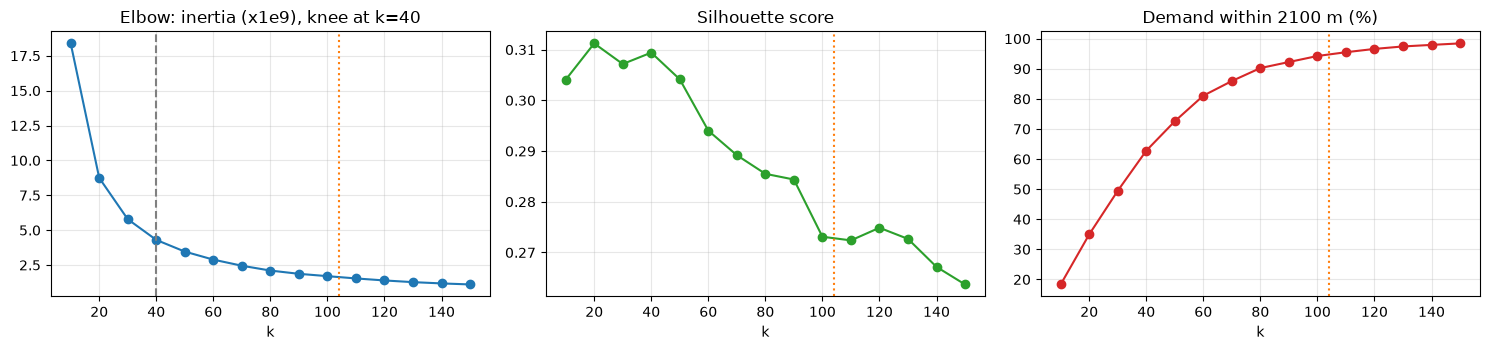

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
k,1.000000e+01,2.000000e+01,3.000000e+01,4.000000e+01,5.000000e+01,6.000000e+01,7.000000e+01,8.000000e+01,9.000000e+01,1.000000e+02,1.100000e+02,1.200000e+02,1.300000e+02,1.400000e+02,1.500000e+02
inertia,1.838587e+10,8.744996e+09,5.784984e+09,4.301274e+09,3.463759e+09,2.888386e+09,2.451180e+09,2.104986e+09,1.870985e+09,1.704073e+09,1.540117e+09,1.395942e+09,1.274651e+09,1.183538e+09,1.109627e+09
silhouette,3.040000e-01,3.110000e-01,3.070000e-01,3.090000e-01,3.040000e-01,2.940000e-01,2.890000e-01,2.860000e-01,2.840000e-01,2.730000e-01,2.720000e-01,2.750000e-01,2.730000e-01,2.670000e-01,2.640000e-01
cov_pct,1.834100e+01,3.497400e+01,4.945500e+01,6.278400e+01,7.256300e+01,8.107100e+01,8.593400e+01,9.024800e+01,9.225100e+01,9.425500e+01,9.551100e+01,9.660800e+01,9.742900e+01,9.794600e+01,9.844700e+01


In [14]:
kchk = []
for kk in range(10, 151, 10):
    Ck, lab, inert = kmeans(X, w, kk, n_init=5)
    kchk.append({"k": kk, "inertia": inert, "silhouette": silhouette_score(X, lab), "cov_pct": cov(Ck, X, w)})
kchk = pd.DataFrame(kchk)
# Kneedle: normalise both axes to 0-1; the knee is where the decreasing curve sits furthest below the straight line between its ends
kx = (kchk.k - kchk.k.min()) / (kchk.k.max() - kchk.k.min())
ky = (kchk.inertia - kchk.inertia.min()) / (kchk.inertia.max() - kchk.inertia.min())
gap = (1 - kx) - ky
knee = int(kchk.k[gap.idxmax()])
# sharpness: drop in inertia per +10 clusters just before vs just after the knee (a sharp elbow has a large ratio)
i_ = gap.idxmax(); before = kchk.inertia[i_ - 1] - kchk.inertia[i_] if i_ > 0 else np.nan; after = kchk.inertia[i_] - kchk.inertia[i_ + 1]
print(f"elbow (Kneedle) at k = {knee}; inertia drop before/after the knee = {before / after:.2f}x | "
      f"silhouette peak at k = {int(kchk.k[kchk.silhouette.idxmax()])} ({kchk.silhouette.max():.3f}), {kchk.silhouette.iloc[-1]:.3f} at k = 150")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(kchk.k, kchk.inertia / 1e9, marker="o"); ax[0].axvline(knee, ls="--", c="grey"); ax[0].set_title(f"Elbow: inertia (x1e9), knee at k={knee}")
ax[1].plot(kchk.k, kchk.silhouette, marker="o", c="tab:green"); ax[1].set_title("Silhouette score")
ax[2].plot(kchk.k, kchk.cov_pct, marker="o", c="tab:red"); ax[2].set_title(f"Demand within {R} m (%)")
for a in ax: a.axvline(P, c="tab:orange", ls=":"); a.set_xlabel("k"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "k_check.png", dpi=130); plt.show()
kchk.round(3).T

Seed stability.

In [15]:
seeds = []
for s_ in range(1, CFG["n_seeds"] + 1):
    Cs, _, ins = kmeans(X, w, P, seed=CFG["seed"] + s_)
    d_ = nearest(K, Cs)
    seeds.append({"seed": CFG["seed"] + s_, "fit_vs_base_pct": 100 * (ins / K_inert - 1), "median_shift_m": np.median(d_), "p90_shift_m": np.quantile(d_, 0.9)})
seeds = pd.DataFrame(seeds); seeds.agg(["mean", "max"]).round(1)

,seed,fit_vs_base_pct,median_shift_m,p90_shift_m
mean,47.5,0.3,915.7,1727.8
max,52.0,1.0,1103.4,1875.1


Monte Carlo: demand weights redrawn (lambda, theta, noise). Control: same weights, new seed.

In [16]:
def km_persistence(perturb):
    rng = np.random.default_rng(CFG["seed"] + 1000); h1 = np.zeros(P); h2 = np.zeros(P); cv = []
    for i in range(CFG["mc_runs"]):
        wp = dw_mc(dem, rng, CFG["mc_sigma"], CFG["mc_lam"], CFG["mc_conc"], R_col=R_COL) if perturb else w
        S = move_inside(kmeans(X, wp, P, seed=CFG["seed"] + i, n_init=5)[0])
        dd = nearest(K, S); h1 += dd <= 1000; h2 += dd <= 2000; cv.append(cov(S, X, w))
    return h1 / CFG["mc_runs"], h2 / CFG["mc_runs"], np.array(cv)

with Timer("K-means Monte Carlo (50 runs)"):
    kp1, kp2, kcv = km_persistence(True)
kc1, kc2, _ = km_persistence(False)
pd.DataFrame({"robust_1km": [(kp1 >= CFG["robust"]).sum(), (kc1 >= CFG["robust"]).sum()],
              "robust_2km": [(kp2 >= CFG["robust"]).sum(), (kc2 >= CFG["robust"]).sum()],
              "cov_min": [kcv.min(), np.nan], "cov_max": [kcv.max(), np.nan]}, index=["weights redrawn", "control: seed only"]).round(1)

,robust_1km,robust_2km,cov_min,cov_max
weights redrawn,23,92,92.4,95.9
control: seed only,28,96,NaN,NaN


## 8. MCLP (Scenario A)
Main run: 206 candidates on the 3 km grid (M1). Then 2 km and 1 km candidates.

In [17]:
S3 = xy(C3)
with Timer("MCLP p=104, 3 km candidates"):
    o3, cv3, inf3 = mclp(w, within(X, S3, R), P, within(X, S3, CFG["R_tie"]))
M = S3[o3]; LAYOUTS["A_mclp_104_c3km"] = M
print(f"MCLP 3 km candidates: {100 * cv3 / w.sum():.2f}% | status {inf3['status']} gap {inf3['gap']:.4f} | same sites as grid {int((nearest(M, G3) < 1).sum())}")

MCLP 3 km candidates: 94.29% | status 0 gap 0.0000 | same sites as grid 77


In [18]:
cs_rows = [{"candidates": "3 km grid (206)", "cov_pct": 100 * cv3 / w.sum(), "mean_dist_m": np.average(nearest(X, M), weights=w), **inf3}]
MCLP_C = {"3km": M}
for nm, S, tl in [("2 km grid (428)", xy(C2), CFG["tl_slow"]), ("1 km cells (1570)", X, CFG["tl_slow"])]:
    with Timer(f"MCLP p=104, {nm}"):
        o_, cv_, inf_ = mclp(w, within(X, S, R), P, None, tl=tl)
    MCLP_C[nm.split()[0] + "km"] = S[o_]
    cs_rows.append({"candidates": nm, "cov_pct": 100 * cv_ / w.sum(), "mean_dist_m": np.average(nearest(X, S[o_]), weights=w), **inf_})
cs_rows.append({"candidates": "K-means (free placement)", "cov_pct": cov(K, X, w), "mean_dist_m": np.average(nearest(X, K), weights=w)})
LAYOUTS["A_mclp_104_c2km"], LAYOUTS["A_mclp_104_c1km"] = MCLP_C["2km"], MCLP_C["1km"]
pd.DataFrame(cs_rows).round(4)

,candidates,cov_pct,mean_dist_m,status,gap,tie_status
0,3 km grid (206),94.2940,1257.8898,0.0,0.0000,0.0
1,2 km grid (428),95.6252,1293.4561,0.0,0.0001,NaN
2,1 km cells (1570),98.8437,1335.3088,1.0,0.0020,NaN
3,K-means (free placement),95.1354,1140.4611,NaN,NaN,NaN


Radius sensitivity (3 km candidates, tie-break on).

In [19]:
rad = []
for r_ in CFG["radii"]:
    o_, cv_, inf_ = mclp(w, within(X, S3, r_), P, within(X, S3, min(CFG["R_tie"], r_ / 2)))
    LAYOUTS[f"A_mclp_104_R{r_}"] = S3[o_]
    rad.append({"R_m": r_, "cov_own_R": 100 * cv_ / w.sum(), "cov_2100": cov(S3[o_], X, w), "status": inf_["status"]})
pd.DataFrame(rad).round(1)

,R_m,cov_own_R,cov_2100,status
0,1500,71.3,92.3,0
1,2100,94.3,94.3,0
2,3000,100.0,80.8,0


Monte Carlo (same draws as K-means). Persistence = share of runs a base site is reopened.

In [20]:
A3, A3t = within(X, S3, R), within(X, S3, CFG["R_tie"])
rng = np.random.default_rng(CFG["seed"] + 1000); opened = np.zeros(len(S3)); mcv = []
with Timer("MCLP Monte Carlo (50 runs)"):
    for i in range(CFG["mc_runs"]):
        wp = dw_mc(dem, rng, CFG["mc_sigma"], CFG["mc_lam"], CFG["mc_conc"], R_col=R_COL)
        o_, _, _ = mclp(wp, A3, P, A3t); opened[o_] += 1; mcv.append(cov(S3[o_], X, w))
mp_ = opened[o3] / CFG["mc_runs"]
print(f"MCLP robust sites {(mp_ >= CFG['robust']).sum()}/{P} | coverage {min(mcv):.1f}-{max(mcv):.1f}%")

MCLP robust sites 89/104 | coverage 93.5-94.3%


## 9. Scenario A scorecard

In [21]:
base = {"Grid 3 km": G3, "K-means": K, "MCLP (3 km cand.)": M, "MCLP (1 km cand.)": MCLP_C["1km"],
        "Existing 4W (98)": E98, "Existing all (1,323)": E_ALL}
cardA = card([score(S, n) for n, S in base.items()]); cardA.T

layout,Grid 3 km,K-means,MCLP (3 km cand.),MCLP (1 km cand.),Existing 4W (98),"Existing all (1,323)"
stations,104.0,104.0,104.0,104.0,98.0,1323.0
a_model_demand_cov,85.0,95.1,94.3,98.8,65.8,95.1
a_mean_dist_m,1450.2,1140.5,1257.9,1335.3,2148.1,659.5
a_p95_dist_m,3006.6,2095.1,2172.8,2000.0,6242.5,2034.2
b_population_cov,83.7,97.5,97.0,99.6,68.9,97.9
b_ev_reg_cov,85.7,97.8,97.3,99.6,70.4,97.6
b_area_cov,65.7,78.5,73.9,89.7,39.4,78.0
b_max_dist_m,9658.4,5533.7,7760.3,6063.2,14033.2,10300.5
c_worst_sc_q_pop,79.7,95.8,90.7,98.9,58.6,94.8
c_worst_sc_q_cells,76.0,93.5,86.7,98.0,44.7,93.4


Equity: population coverage within 2.1 km by SC quintile (population-weighted groups).

In [22]:
eq = {}
for n, S in base.items():
    d_ = nearest(X, S)
    eq[n] = (100 * pd.Series(POP * (d_ <= R)).groupby(dem["sc_q_pop"].values, observed=True).sum()
             / pd.Series(POP).groupby(dem["sc_q_pop"].values, observed=True).sum()).round(1)
pd.DataFrame(eq).T

,Q1,Q2,Q3,Q4,Q5
Grid 3 km,88.5,82.8,85.6,79.7,82.3
K-means,98.3,98.5,97.4,95.8,97.4
MCLP (3 km cand.),99.5,99.3,97.1,90.7,99.2
MCLP (1 km cand.),100.0,99.8,99.7,98.9,99.8
Existing 4W (98),85.4,75.8,58.6,61.5,65.1
"Existing all (1,323)",100.0,98.7,98.2,94.8,98.2


Station load (demand nearest to each station, as a multiple of the average).

In [23]:
avg = w.sum() / P
pd.DataFrame({n: pd.Series(np.bincount(cKDTree(S).query(X)[1], weights=w, minlength=len(S)) / avg).describe(percentiles=[.5, .9])
              for n, S in list(base.items())[:4]}).T[["50%", "90%", "max"]].round(2)

,50%,90%,max
Grid 3 km,0.76,2.22,2.92
K-means,0.93,1.67,2.48
MCLP (3 km cand.),0.79,1.91,2.74
MCLP (1 km cand.),0.74,2.03,3.66


## 10. Scenario B: build on existing confirmed 4W sites

In [24]:
def scenario_b(E, p_new=None):
    _, cells3 = GRID[3]
    Eg = gpd.GeoDataFrame(geometry=gpd.points_from_xy(E[:, 0], E[:, 1]), crs=CRS)
    has = gpd.sjoin(cells3[cells3.station][["cell_id", "geometry"]], Eg, predicate="contains")["cell_id"].unique()
    gB = xy(GRID[3][0][~GRID[3][0].cell_id.isin(has)])
    p_ = len(gB) if p_new is None else p_new
    SB = np.vstack([S3, E]); fx = np.arange(len(S3), len(SB))
    o_, _, inf_ = mclp(w, within(X, SB, R), p_, within(X, SB, CFG["R_tie"]), fixed=fx)
    mB = SB[np.setdiff1d(o_, fx)]
    kB = kmeans_fixed(X, w, E, p_)
    return {"Grid B": gB, "K-means B": kB, "MCLP B": mB}

rowsB = [score(E98, "Existing 98 only")]
for p_new in [None, P]:
    sb = scenario_b(E98, p_new)
    for n, S in sb.items():
        if n == "Grid B" and p_new is not None: continue
        LAYOUTS[f"B_{n.split()[0].lower()}_{len(S)}new"] = S
        rowsB.append(score(np.vstack([E98, S]), f"{n}: 98 + {len(S)} new"))
cardB = card(rowsB)
cardB[["stations", "a_model_demand_cov", "a_mean_dist_m", "b_population_cov", "b_area_cov", "c_worst_sc_q_pop", "f_road_3km_demand_cov"]]

,stations,a_model_demand_cov,a_mean_dist_m,b_population_cov,b_area_cov,c_worst_sc_q_pop,f_road_3km_demand_cov
layout,,,,,,,
Existing 98 only,98,65.8,2148.1,68.9,39.4,58.6,56.8
Grid B: 98 + 59 new,157,88.0,1324.3,87.4,68.5,81.5,76.5
K-means B: 98 + 59 new,157,93.9,1082.6,94.9,76.7,93.2,85.2
MCLP B: 98 + 59 new,157,95.4,1195.3,97.2,78.5,94.3,81.8
K-means B: 98 + 104 new,202,98.6,895.0,99.6,89.1,98.7,91.8
MCLP B: 98 + 104 new,202,99.4,1082.6,99.8,94.4,99.6,86.1


Check: all 149 confirmed 4W sites fixed (D3), 104 new.

In [25]:
sb149 = scenario_b(E149, P)
pd.Series({n: cov(np.vstack([E149, S]), X, w) for n, S in sb149.items()}).round(2)

Grid B       88.03
K-means B    98.23
MCLP B       99.44
dtype: float64

New stations needed on top of the 98 (MCLP, 3 km candidates).

In [26]:
SB = np.vstack([S3, E98]); fx = np.arange(len(S3), len(SB)); AB = within(X, SB, R)
curve = pd.DataFrame([{"new": p_, "cov_pct": 100 * mclp(w, AB, p_, fixed=fx)[1] / w.sum()} for p_ in [0, 10, 20, 30, 40, 50, 60, 80, 104, 130, 160]])
print({t: int(curve.loc[curve.cov_pct >= t, "new"].min()) for t in [90, 95, 99]})
curve.round(1).T

{90: 40, 95: 60, 99: 104}


,0,1,2,3,4,5,6,7,8,9,10
new,0.0,10.0,20.0,30.0,40.0,50.0,60.0,80.0,104.0,130.0,160.0
cov_pct,65.8,77.2,83.9,88.2,91.4,93.7,95.5,97.9,99.4,100.0,100.0


## 11. Sensitivity: demand surface
Each method rebuilt and scored on each surface (104 stations, 2.1 km, MCLP on 3 km candidates).

In [27]:
d5 = gpd.read_file(CFG["demand_500"], layer="demand_weights").to_crs(CRS)
SURF = {"1 km: team": (X, dem["w_team"].to_numpy()), "1 km: EV + destinations": (X, dem["w_ev"].to_numpy()),
        "1 km: EV registrations": (X, EVR), "1 km: population": (X, POP),
        "500 m: team": (xy(d5), d5["weight"].to_numpy(float)),
        "ward: demand_w": (XW, master["demand_w"].to_numpy(float)), "ward: population": (XW, master["population"].to_numpy(float))}
srows, SL = [], {}
for nm, (P_, wt) in SURF.items():
    Kq = move_inside(kmeans(P_, wt, P, n_init=10)[0]); oq, _, _ = mclp(wt, within(P_, S3, R), P, within(P_, S3, CFG["R_tie"]))
    SL[nm] = (Kq, S3[oq])
    srows.append({"surface": nm, "grid": cov(G3, P_, wt), "kmeans": cov(Kq, P_, wt), "mclp": cov(S3[oq], P_, wt),
                  "kmeans_on_1km_team": cov(Kq, X, dem["w_team"].to_numpy()), "mclp_on_1km_team": cov(S3[oq], X, dem["w_team"].to_numpy())})
surf = pd.DataFrame(srows).set_index("surface").round(1); surf

,grid,kmeans,mclp,kmeans_on_1km_team,mclp_on_1km_team
surface,,,,,
1 km: team,83.8,95.3,94.4,95.3,94.4
1 km: EV + destinations,85.0,94.6,94.3,94.1,94.2
1 km: EV registrations,85.7,97.6,98.1,91.0,92.8
1 km: population,83.7,97.5,98.1,91.2,93.4
500 m: team,84.1,94.7,94.0,95.1,93.5
ward: demand_w,85.5,99.9,100.0,88.7,86.5
ward: population,84.4,99.7,100.0,88.9,86.0


In [28]:
print("rank correlation with 1 km team weight:",
      {k: round(spearmanr(dem["w_team"], v)[0], 3) for k, v in [("EV + destinations", dem["w_ev"]), ("EV registrations", EVR), ("population", POP)]})
wards_g = gpd.read_file(CFG["gis"], layer="wards").to_crs(CRS)
dl12 = wards_g[wards_g.ward_no.map(master["rto_zone"]) == "DL12"].union_all()
print("stations in Burari (DL12):", {nm: int(sum(dl12.contains(shapely.Point(*p)) for p in SL[nm][0])) for nm in ["ward: demand_w", "ward: population", "1 km: team"]}, "(K-means)")

rank correlation with 1 km team weight: {'EV + destinations': np.float64(0.978), 'EV registrations': np.float64(0.856), 'population': np.float64(0.884)}
stations in Burari (DL12): {'ward: demand_w': 7, 'ward: population': 4, '1 km: team': 5} (K-means)


## 12. Sensitivity: number of stations
MCLP on 1 km cell centres here (the 206 grid points run out at large budgets). Solver status recorded.

In [29]:
A21, A10 = within(X, X, R), within(X, X, CFG["R_tie"])
brows = []
for k in CFG["budgets"]:
    Ck = move_inside(kmeans(X, w, k, n_init=10)[0])
    t0 = time.time(); o_, _, inf_ = mclp(w, A21, k, A10, tl=CFG["tl_budget"]); TIMES[f"MCLP budget {k}"] = time.time() - t0
    LAYOUTS[f"A_kmeans_{k}"], LAYOUTS[f"A_mclp1km_{k}"] = Ck, X[o_]
    for nm, S in [("K-means", Ck), ("MCLP", X[o_])]:
        r_ = score(S, f"{nm} ({k})", road=False); r_.update(method=nm, budget=k, solver_status=inf_["status"] if nm == "MCLP" else np.nan,
                                                         solver_gap=inf_["gap"] if nm == "MCLP" else np.nan)
        brows.append(r_)
for s, (st, _) in GRID.items():
    r_ = score(xy(st), f"Grid {s} km ({len(st)})", road=False); r_.update(method="Grid", budget=len(st)); brows.append(r_)
bud = pd.DataFrame(brows).set_index("layout").sort_values(["budget", "method"])
bud[["method", "budget", "a_model_demand_cov", "a_mean_dist_m", "b_area_cov", "b_max_dist_m", "c_worst_sc_q_pop", "solver_status", "solver_gap"]].round(3)

,method,budget,a_model_demand_cov,a_mean_dist_m,b_area_cov,b_max_dist_m,c_worst_sc_q_pop,solver_status,solver_gap
layout,,,,,,,,,
Grid 3 km (104),Grid,104,84.973,1450.246,65.680,9658.354,79.715,NaN,NaN
K-means (104),K-means,104,94.644,1142.531,77.497,4784.913,93.623,NaN,NaN
MCLP (104),MCLP,104,98.776,1333.481,89.221,6063.226,98.809,1.0,0.003
Grid 2 km (157),Grid,157,87.236,1232.262,68.331,9093.074,80.105,NaN,NaN
K-means (157),K-means,157,98.742,922.128,90.135,4416.181,98.397,NaN,NaN
MCLP (157),MCLP,157,100.000,1212.483,100.000,2579.573,100.000,0.0,0.000
K-means (178),K-means,178,98.924,865.141,89.966,5325.026,98.827,NaN,NaN
MCLP (178),MCLP,178,100.000,1167.598,100.000,2099.086,100.000,0.0,0.000
K-means (206),K-means,206,99.220,791.010,92.706,4223.717,99.537,NaN,NaN


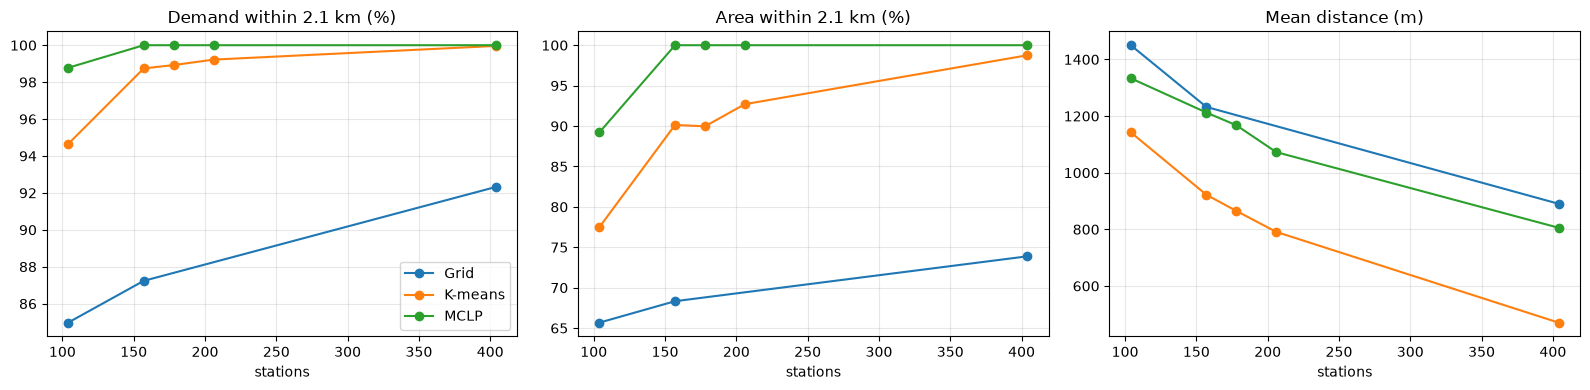

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for m_, c in [("Grid", "tab:blue"), ("K-means", "tab:orange"), ("MCLP", "tab:green")]:
    d_ = bud[bud.method == m_].sort_values("budget")
    for ax, col, t in zip(axes, ["a_model_demand_cov", "b_area_cov", "a_mean_dist_m"], ["Demand within 2.1 km (%)", "Area within 2.1 km (%)", "Mean distance (m)"]):
        ax.plot(d_.budget, d_[col], marker="o", color=c, label=m_); ax.set_title(t); ax.set_xlabel("stations"); ax.grid(alpha=.3)
axes[0].legend(); plt.tight_layout(); plt.savefig(OUT / "budget_curves.png", dpi=130); plt.show()

### Minimum stations to reach every cell (set cover)
Fewest stations such that every 1 km cell has a station within the service distance (Location Set Covering Problem, Toregas et al. 1971). Answers "how many stations does Delhi's goal of charging within 3 km of anywhere need?" Three readings: straight-line 2.1 km on the 206 grid points, straight-line 2.1 km anywhere (1 km cell centres), and 3 km by road anywhere. Cells that no candidate can reach are left out and counted. Solver status and the proven lower bound are recorded.

In [31]:
def set_cover(A, tl=CFG["tl_slow"]):
    reach = np.asarray(A.sum(1)).ravel() > 0
    r_ = milp(np.ones(A.shape[1]), constraints=[LinearConstraint(A[reach], 1, np.inf)], integrality=np.ones(A.shape[1]),
              bounds=Bounds(0, 1), options=dict(time_limit=tl))
    return {"stations": int(round(r_.fun)), "lower_bound": round(float(getattr(r_, "mip_dual_bound", np.nan) or np.nan), 1),
            "status": r_.status, "gap": getattr(r_, "mip_gap", np.nan), "unreachable_cells": int((~reach).sum())}

sc_rows = []
with Timer("set cover"):
    sc_rows.append({"reading": "2.1 km straight-line, 206 grid points", **set_cover(within(X, S3, R))})
    sc_rows.append({"reading": "2.1 km straight-line, anywhere (1 km cells)", **set_cover(within(X, X, R))})
    if ROAD is not None:
        if "Dr1" not in globals():
            Dr1 = ROAD.dist_to(X, X)
        sc_rows.append({"reading": "3 km by road, anywhere (1 km cells)", **set_cover(csr_matrix((Dr1 <= 3000).astype(float)))})
setcover = pd.DataFrame(sc_rows).set_index("reading"); setcover

,stations,lower_bound,status,gap,unreachable_cells
reading,,,,,
"2.1 km straight-line, 206 grid points",178,178.0,0,0.000000,1
"2.1 km straight-line, anywhere (1 km cells)",133,126.0,1,0.052632,0
"3 km by road, anywhere (1 km cells)",224,224.0,0,0.000000,2


## 13. Extensions

In [32]:
ext = []
def add_ext(name, S, Sbase):
    r_ = score(S, name); r_["sites_moved_pct"] = 100 - agree(S, Sbase); ext.append(r_); LAYOUTS["ext_" + name] = S

o_, _, _ = mclp(w, within(X, REAL, R), P, within(X, REAL, CFG["R_tie"])); add_ext("MCLP on OSM parking/fuel", REAL[o_], M)
add_ext("p-median on OSM parking/fuel", REAL[pmedian(w, X, REAL, P)], K)
add_ext("p-median, 1 km cells", X[pmedian(w, X, X, P)], K)
o_ = mclp_gradual(w, X, S3, P); add_ext("MCLP gradual (1 km full, 3 km zero)", S3[o_], M)
if ROAD is not None:
    with Timer("road matrices"):
        Dr3 = ROAD.dist_to(X, S3); Dr1 = ROAD.dist_to(X, X)
    o_, _, _ = mclp(w, csr_matrix((Dr3 <= 3000).astype(float)), P, csr_matrix((Dr3 <= 1500).astype(float))); add_ext("MCLP, 3 km by road", S3[o_], M)
    add_ext("p-median, road, 1 km cells", X[pmedian(w, X, X, P, dist=np.where(np.isfinite(Dr1), Dr1, 1e7))], K)
extA = card(ext); extA[["sites_moved_pct", "a_model_demand_cov", "a_mean_dist_m", "b_area_cov", "c_worst_sc_q_pop", "e_sites_500m_parking_fuel"]
                      + [c for c in extA.columns if c.startswith("f_road_mean")]]

,sites_moved_pct,a_model_demand_cov,a_mean_dist_m,b_area_cov,c_worst_sc_q_pop,e_sites_500m_parking_fuel,f_road_mean_dist_m
layout,,,,,,,
MCLP on OSM parking/fuel,69.2,88.5,1482.4,65.4,84.8,100.0,2489.0
p-median on OSM parking/fuel,54.8,86.4,1341.6,60.2,83.1,100.0,2279.6
"p-median, 1 km cells",32.7,91.6,1087.4,69.3,90.4,33.7,1894.0
"MCLP gradual (1 km full, 3 km zero)",13.5,93.4,1239.1,72.5,90.6,26.9,2212.0
"MCLP, 3 km by road",18.3,92.1,1290.1,71.3,88.7,24.0,2181.1
"p-median, road, 1 km cells",39.4,90.3,1129.6,67.9,90.0,36.5,1742.7


Capacity cap: each station serves at most alpha x the average load.

In [33]:
caps = []
for a_ in [1.25, 1.5, 2.0]:
    Ck = kmeans_capacitated(X, w, P, a_ * avg); om, served = mclp_capacitated(w, X, S3, P, R, a_ * avg)
    for nm, S, Sb in [(f"K-means cap {a_}", Ck, K), (f"MCLP cap {a_}", S3[om], M)]:
        r_ = score(S, nm, road=False); r_["sites_moved_pct"] = 100 - agree(S, Sb); caps.append(r_)
card(caps)[["sites_moved_pct", "a_model_demand_cov", "a_mean_dist_m", "c_worst_sc_q_pop"]]

,sites_moved_pct,a_model_demand_cov,a_mean_dist_m,c_worst_sc_q_pop
layout,,,,
K-means cap 1.25,37.5,93.6,1149.9,94.3
MCLP cap 1.25,4.8,93.9,1261.0,90.6
K-means cap 1.5,39.4,94.6,1145.9,93.6
MCLP cap 1.5,1.0,94.3,1256.9,90.6
K-means cap 2.0,42.3,94.6,1141.8,93.6
MCLP cap 2.0,0.0,94.3,1257.9,90.7


## 14. Agreement between methods

In [34]:
trio = {"Grid": G3, "K-means": K, "MCLP 3 km": M, "MCLP 1 km": MCLP_C["1km"]}
pd.DataFrame({a: {b: agree(trio[a], trio[b]) for b in trio} for a in trio}).T.round(0)

,Grid,K-means,MCLP 3 km,MCLP 1 km
Grid,100.0,23.0,74.0,29.0
K-means,23.0,100.0,27.0,35.0
MCLP 3 km,74.0,27.0,100.0,30.0
MCLP 1 km,29.0,35.0,30.0,100.0


In [35]:
gm = nearest(G3, M) < 1
dk = nearest(G3, K)
cons = pd.DataFrame({"x": G3[:, 0], "y": G3[:, 1], "grid_and_mclp": gm, "kmeans_dist_m": dk})
cons["all_three_1km"] = cons.grid_and_mclp & (cons.kmeans_dist_m <= 1000)
cons["kmeans_persistence"] = kp1[cKDTree(K).query(G3)[1]]
cons["mclp_persistence"] = opened[cKDTree(S3).query(G3)[1]] / CFG["mc_runs"]
cons["robust_all"] = cons.all_three_1km & (cons.kmeans_persistence >= 0.5) & (cons.mclp_persistence >= CFG["robust"])
cons["ward_no"] = dem["ward_no"].to_numpy()[cKDTree(X).query(G3)[1]]; cons["ward_name"] = cons.ward_no.map(master["ward_name"])
print(f"grid & MCLP same site {gm.sum()} | all three within 1 km {cons.all_three_1km.sum()} | also stable {cons.robust_all.sum()}")
cons[cons.all_three_1km].sort_values("kmeans_dist_m")[["ward_no", "ward_name", "kmeans_dist_m", "kmeans_persistence", "mclp_persistence"]].round(2)

grid & MCLP same site 77 | all three within 1 km 22 | also stable 14


,ward_no,ward_name,kmeans_dist_m,kmeans_persistence,mclp_persistence
37,4,Alipur,53.36,0.20,0.68
74,147,Kotla Mubarakpur,132.97,0.52,0.98
84,201,Lalita Park,177.12,0.82,0.98
63,160,Said-Ul-Ajaib,220.19,0.44,1.00
26,2,Bankner,242.40,0.20,1.00
60,17,Bhalswa,261.75,0.90,1.00
14,110,Kunwar Singh Nagar,461.07,0.20,1.00
6,35,Mundka,461.69,0.20,1.00
55,153,Vasant Vihar,546.22,0.90,1.00
42,133,Mahipalpur,580.38,0.66,0.90


## 15. Maps

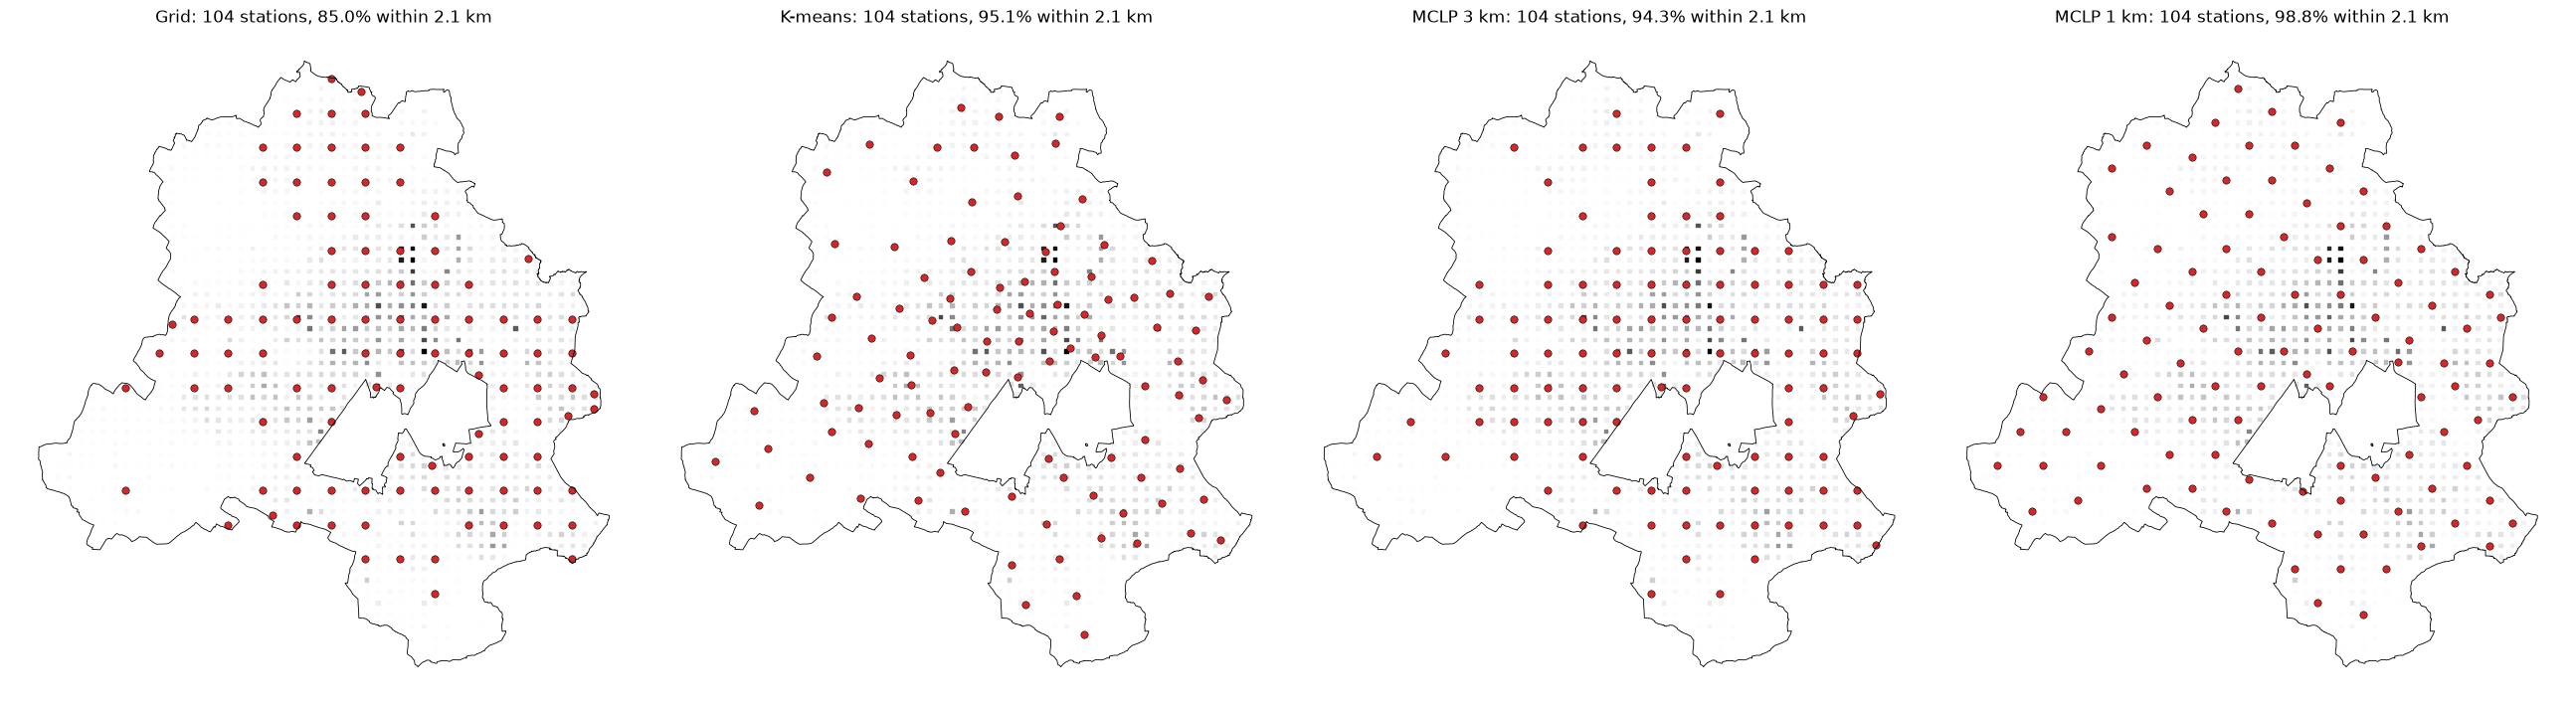

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(26, 8))
for ax, (n, S) in zip(axes, trio.items()):
    study.boundary.plot(ax=ax, color="k", lw=0.6); ax.scatter(X[:, 0], X[:, 1], c=w, s=6, cmap="Greys", marker="s")
    ax.scatter(S[:, 0], S[:, 1], s=28, c="tab:red", edgecolors="k", lw=0.4)
    ax.set_title(f"{n}: {len(S)} stations, {cov(S, X, w):.1f}% within 2.1 km"); ax.set_axis_off(); ax.set_aspect("equal")
plt.tight_layout(); plt.savefig(OUT / "layouts_map.png", dpi=110, bbox_inches="tight"); plt.show()

## 16. Computational cost

In [37]:
cost = pd.Series(TIMES).round(1).rename("seconds").to_frame(); cost

,seconds
demand rebuild,7.3
grid 3 km,0.1
grid 2 km,0.2
grid 1 km,0.8
K-means k=104,0.2
K-means Monte Carlo (50 runs),2.3
"MCLP p=104, 3 km candidates",0.1
"MCLP p=104, 2 km grid (428)",122.1
"MCLP p=104, 1 km cells (1570)",600.0
MCLP Monte Carlo (50 runs),5.0


## 17. Export

In [38]:
gpkg = OUT / "layouts.gpkg"
if gpkg.exists(): gpkg.unlink()
idx = []
for k_, S in LAYOUTS.items():
    lyr = "".join(c if c.isalnum() else "_" for c in k_)[:60]
    gpd.GeoDataFrame({"station_id": np.arange(len(S)), "x": S[:, 0], "y": S[:, 1]}, geometry=gpd.points_from_xy(S[:, 0], S[:, 1]), crs=CRS).to_file(gpkg, layer=lyr)
    idx.append({"layer": lyr, "stations": len(S)})
pts(cons).to_file(gpkg, layer="consensus_sites")
for nm, df in [("scorecard_A", cardA), ("scorecard_B", cardB), ("grid_thresholds", thr), ("k_check", kchk), ("kmeans_seeds", seeds),
               ("mclp_candidate_sets", pd.DataFrame(cs_rows)), ("mclp_radius", pd.DataFrame(rad)), ("equity_sc_pop", pd.DataFrame(eq).T),
               ("scenarioB_curve", curve), ("demand_surfaces", surf), ("budgets", bud), ("extensions", extA), ("capacity", card(caps)),
               ("consensus", cons), ("compute_time", cost), ("set_cover", setcover), ("layers_index", pd.DataFrame(idx))]:
    df.to_csv(OUT / f"{nm}.csv")
json.dump({k: v for k, v in CFG.items()}, open(OUT / "settings.json", "w"), indent=1, default=str)
print(f"saved {len(idx)} layouts and tables to {OUT}")

saved 30 layouts and tables to outputs/final
